## Breast cancer

In [30]:
import pandas as pd
import os

In [37]:
# 加载数据集
file_path = '../ELIFE pancancer ready-to-use data.csv'
data = pd.read_csv(file_path)

In [38]:
positive_samples = data[data['Diagnosis'] == "Breast cancer"]
negative_samples = data[data['Label'] == 0]

num_negative = len(positive_samples) * 1  # 负样本数量是正样本的 1 倍
negative_samples = negative_samples.sample(n=num_negative, random_state=42)  # 随机采样负样本

# 合并正负样本
breast_sample = pd.concat([positive_samples, negative_samples], ignore_index=True)
breast_sample = breast_sample.drop(columns=["SampleID", "Cohort", "Diagnosis"])
breast_sample.to_csv("breast_sample.csv", index=False)

In [39]:
breast_data = pd.read_csv("breast_sample.csv")
breast_data

,Label,TMD_1,TMD_2,TMD_3,TMD_4,TMD_5,TMD_6,TMD_7,TMD_8,TMD_9,...,MOTIF_END_TTCG,MOTIF_END_TTCT,MOTIF_END_TTGA,MOTIF_END_TTGC,MOTIF_END_TTGG,MOTIF_END_TTGT,MOTIF_END_TTTA,MOTIF_END_TTTC,MOTIF_END_TTTG,MOTIF_END_TTTT
0,1,0.965447,0.134228,0.051155,0.141777,0.995098,0.942529,0.968254,0.300000,0.140625,...,0.000351,0.004416,0.003916,0.002454,0.003231,0.003478,0.005930,0.004735,0.004640,0.008361
1,1,0.960526,0.052632,0.046954,0.070341,0.931122,0.943966,1.000000,0.194313,0.214182,...,0.000362,0.004477,0.003920,0.002485,0.003396,0.003507,0.005892,0.004876,0.004640,0.008428
2,1,0.977358,0.162791,0.035363,0.179856,0.971193,0.909091,0.928571,0.367412,0.162437,...,0.000351,0.004417,0.003934,0.002483,0.003176,0.003516,0.006063,0.004917,0.004646,0.008551
3,1,0.971576,0.194444,0.027308,0.098697,0.952586,0.902299,1.000000,0.211806,0.115493,...,0.000352,0.004391,0.003840,0.002459,0.003224,0.003470,0.005855,0.004802,0.004518,0.008331
4,1,0.695946,0.138132,0.176598,0.223963,0.926108,0.878049,0.977528,0.293173,0.397436,...,0.000372,0.004394,0.004086,0.002530,0.003478,0.003566,0.005995,0.004805,0.004723,0.008305
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
441,0,0.977143,0.098413,0.063492,0.088183,0.937238,1.000000,0.947368,0.063830,0.097436,...,0.000374,0.004452,0.003997,0.002523,0.003373,0.003636,0.005970,0.004945,0.004793,0.008590
442,0,0.948718,0.050273,0.093722,0.054915,0.928977,0.866667,0.910112,0.243968,0.216837,...,0.000387,0.004708,0.003880,0.002599,0.003288,0.003633,0.005846,0.004990,0.004773,0.008784
443,0,0.925466,0.304348,0.024272,0.090206,0.905660,0.962264,0.961538,0.206897,0.234043,...,0.000411,0.004436,0.003844,0.002564,0.003408,0.003597,0.005511,0.004653,0.004744,0.008095
444,0,0.970414,0.064706,0.105360,0.106884,0.990476,0.818182,1.000000,0.068965,0.111111,...,0.000374,0.004587,0.003844,0.002526,0.003272,0.003597,0.005970,0.005034,0.004779,0.008740


### Fscore

In [1]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "breast_sample_FscoreSorted.csv"
data = pd.read_csv(file_path)

In [2]:
data

,class,MOTIF_END_CAAC,MOTIF_END_CAGT,MOTIF_END_CATC,MOTIF_END_GACT,MOTIF_END_CAAG,MOTIF_END_TGCA,MOTIF_END_CAGA,MOTIF_END_CGAA,MOTIF_END_TAGC,...,GWMD_chr1_173,CNA_5:44000001-45000000,flen_218,GWFP_total_15:55000001-60000000,CNA_5:13000001-14000000,CNA_11:95000001-96000000,CNA_3:132000001-133000000,GWFP_total_14:40000001-45000000,GWFP_long_12:95000001-100000000,CNA_1:81000001-82000000
0,1,0.003608,0.005748,0.004128,0.002793,0.006604,0.004784,0.009053,0.000694,0.002802,...,0.862288,1.03755,0.001359,0.126605,1.03207,0.923676,1.01181,-0.164091,-1.33233,1.045720
1,1,0.003710,0.006004,0.004354,0.002654,0.007001,0.004583,0.009886,0.000653,0.002788,...,0.834347,1.18040,0.001076,0.152605,1.05522,0.911829,1.16631,-0.219148,-1.22115,0.982301
2,1,0.003603,0.005624,0.004209,0.002708,0.006578,0.004733,0.009014,0.000681,0.002802,...,0.852766,1.04397,0.001298,0.327240,1.05314,0.923003,1.04468,0.052232,-1.23196,1.006950
3,1,0.003562,0.005665,0.004130,0.002745,0.006603,0.004872,0.009088,0.000698,0.002799,...,0.840639,1.05898,0.001531,0.321785,1.06220,0.915858,1.11031,-0.198155,-1.25024,1.051490
4,1,0.003683,0.005842,0.004136,0.002619,0.006833,0.004480,0.009524,0.000672,0.002923,...,0.825942,1.09489,0.000922,0.052025,1.06251,0.895950,1.00745,0.120711,-1.15603,1.048080
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
441,0,0.003496,0.005631,0.004066,0.002673,0.006527,0.005118,0.009070,0.000702,0.002767,...,0.854974,1.14898,0.001697,0.063760,1.05421,0.904594,1.12101,-0.258468,-1.21114,1.044480
442,0,0.003351,0.005359,0.004113,0.002734,0.005770,0.005404,0.007958,0.000767,0.002551,...,0.833737,1.22843,0.001542,0.038416,0.99805,0.886618,1.17710,-0.311287,-1.18232,0.996855
443,0,0.003230,0.005557,0.003810,0.002965,0.006036,0.005511,0.008416,0.000851,0.002696,...,0.844097,1.13908,0.001267,0.048458,1.05873,0.905270,1.16914,-0.389158,-1.17771,1.071760
444,0,0.003439,0.005453,0.004142,0.002760,0.006079,0.005020,0.008365,0.000701,0.002622,...,0.812989,1.13224,0.002008,0.141709,1.01994,0.914839,1.09211,-0.279453,-1.33323,1.028360


In [3]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [4]:
y_train.value_counts()

class
0    142
1    142
Name: count, dtype: int64

In [5]:
all_features = X_train.columns.tolist()
auc_train_scores_Fscore = []
auc_val_scores_Fscore = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.1
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [6]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_Fscore.append(auc_train)
    auc_val_scores_Fscore.append(auc_val)
    
    for_num += 1
    print({for_num})

    if for_num >200:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
{3}
验证集 AUC 开始下降（0.7674 → 0.7168），连续次数：1
{4}
{5}
验证集 AUC 开始下降（0.7365 → 0.7299），连续次数：1
{6}
{7}
{8}
过拟合检测：训练集 AUC=0.8795, 验证集 AUC=0.7766，连续次数：1
{9}
验证集 AUC 开始下降（0.7766 → 0.7589），连续次数：1
{10}
{11}
过拟合检测：训练集 AUC=0.8621, 验证集 AUC=0.7508，连续次数：1
验证集 AUC 开始下降（0.7782 → 0.7508），连续次数：1
{12}
过拟合检测：训练集 AUC=0.8751, 验证集 AUC=0.7677，连续次数：2
{13}
{14}
过拟合检测：训练集 AUC=0.9015, 验证集 AUC=0.7955，连续次数：1
{15}
{16}
过拟合检测：训练集 AUC=0.8936, 验证集 AUC=0.7932，连续次数：1
验证集 AUC 开始下降（0.8094 → 0.7932），连续次数：1
{17}
{18}
过拟合检测：训练集 AUC=0.8963, 验证集 AUC=0.7785，连续次数：1
验证集 AUC 开始下降（0.8017 → 0.7785），连续次数：1
{19}
{20}
{21}
过拟合检测：训练集 AUC=0.9033, 验证集 AUC=0.7886，连续次数：1
验证集 AUC 开始下降（0.8248 → 0.7886），连续次数：1
{22}
过拟合检测：训练集 AUC=0.9063, 验证集 AUC=0.7716，连续次数：2
验证集 AUC 开始下降（0.7886 → 0.7716），连续次数：2
{23}
{24}
过拟合检测：训练集 AUC=0.9129, 验证集 AUC=0.8117，连续次数：1
验证集 AUC 开始下降（0.8480 → 0.8117），连续次数：1
{25}
过拟合检测：训练集 AUC=0.8962, 验证集 AUC=0.7847，连续次数：2
验证集 AUC 开始下降（0.8117 → 0.7847），连续次数：2
{26}
{27}
{28}
验证集 AUC 开始下降（0.8542 → 0.8086），连续次数：1
{29}
{30}
过拟合检测：训练集 AU

In [98]:
breast_sample_FscoreSorted = pd.read_csv("breast_sample_FscoreSorted.csv")
breast_sample_FscoreSorted_selected74 = breast_sample_FscoreSorted.iloc[:, :75]
breast_sample_FscoreSorted_selected74.to_csv("../Fscore/breast_sample_FscoreSorted_selected74.csv", index=False)

In [ ]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_Fscore) + 1),
    "Train_AUC": auc_train_scores_Fscore,
    "Validation_AUC": auc_val_scores_Fscore
})

auc_df.to_csv("AUC_scores_Fscore.csv", index=False)

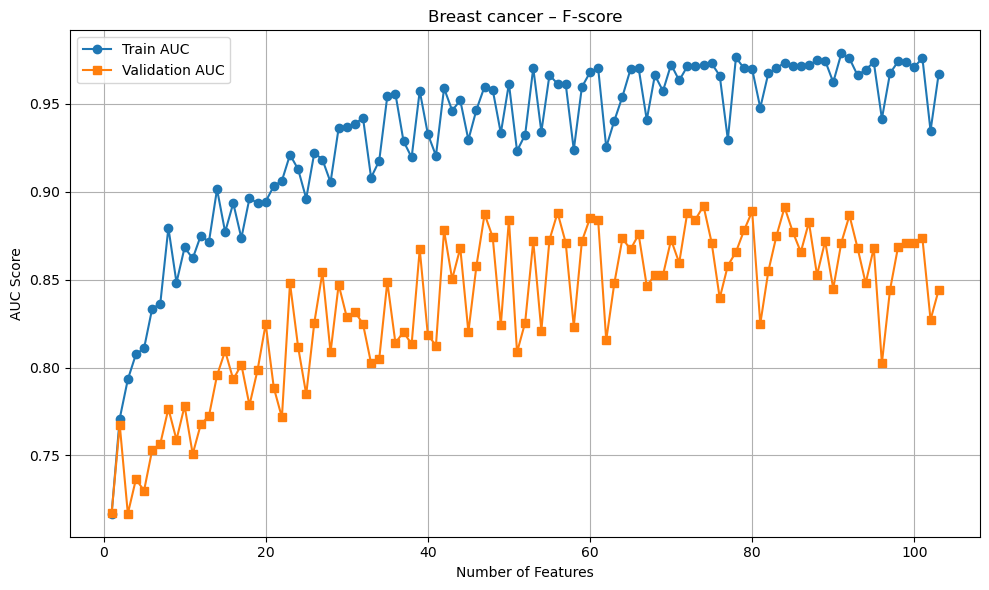

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_Fscore.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Breast cancer – F-score")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_Fscore.png", dpi=300)
plt.show()


### ANOVA

In [43]:
import pandas as pd

# 1. 读取最终的 CSV 文件
csv_file = "breast_sample_AnovaSorted.csv"
df = pd.read_csv(csv_file)

# 2. 读取 ANOVA 排序的特征文件，获取正确的特征名顺序
anova_sorted_file = "../ANOVA/breast_feature_importance.csv" 
with open(anova_sorted_file, "r") as f:
    sorted_feature_names = [line.split()[1] for line in f.readlines()]  # 取出特征名称

# 3. 获取当前 CSV 文件的列名（去掉第一列 class）
original_column_names = list(df.columns[1:])  # 去掉第 1 列类别标签

# 4. 创建新的列名列表（保持类别标签不变）
new_column_names = ["class"] + sorted_feature_names[:len(original_column_names)]

# 5. 重新设置 DataFrame 的列名
df.columns = new_column_names

# 6. 保存修改后的 CSV 文件
df.to_csv("breast_sample_AnovaSorted_corrected.csv", index=False)


In [11]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "breast_sample_AnovaSorted_corrected.csv"
data = pd.read_csv(file_path)

In [12]:
data

,class,MOTIF_END_CAAC,MOTIF_END_CAGT,MOTIF_END_CATC,MOTIF_END_GACT,MOTIF_END_CAAG,MOTIF_END_TGCA,MOTIF_END_CAGA,MOTIF_END_CGAA,MOTIF_END_TAGC,...,GWMD_chr1_173,CNA_5:44000001-45000000,flen_218,GWFP_total_15:55000001-60000000,CNA_5:13000001-14000000,CNA_11:95000001-96000000,CNA_3:132000001-133000000,GWFP_total_14:40000001-45000000,GWFP_long_12:95000001-100000000,CNA_1:81000001-82000000
0,1,0.003608,0.005748,0.004128,0.002793,0.006604,0.004784,0.009053,0.000694,0.002802,...,0.862288,1.03755,0.001359,0.126605,1.03207,0.923676,1.01181,-0.164091,-1.33233,1.045720
1,1,0.003710,0.006004,0.004354,0.002654,0.007001,0.004583,0.009886,0.000653,0.002788,...,0.834347,1.18040,0.001076,0.152605,1.05522,0.911829,1.16631,-0.219148,-1.22115,0.982301
2,1,0.003603,0.005624,0.004209,0.002708,0.006578,0.004733,0.009014,0.000681,0.002802,...,0.852766,1.04397,0.001298,0.327240,1.05314,0.923003,1.04468,0.052232,-1.23196,1.006950
3,1,0.003562,0.005665,0.004130,0.002745,0.006603,0.004872,0.009088,0.000698,0.002799,...,0.840639,1.05898,0.001531,0.321785,1.06220,0.915858,1.11031,-0.198155,-1.25024,1.051490
4,1,0.003683,0.005842,0.004136,0.002619,0.006833,0.004480,0.009524,0.000672,0.002923,...,0.825942,1.09489,0.000922,0.052025,1.06251,0.895950,1.00745,0.120711,-1.15603,1.048080
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
441,0,0.003496,0.005631,0.004066,0.002673,0.006527,0.005118,0.009070,0.000702,0.002767,...,0.854974,1.14898,0.001697,0.063760,1.05421,0.904594,1.12101,-0.258468,-1.21114,1.044480
442,0,0.003351,0.005359,0.004113,0.002734,0.005770,0.005404,0.007958,0.000767,0.002551,...,0.833737,1.22843,0.001542,0.038416,0.99805,0.886618,1.17710,-0.311287,-1.18232,0.996855
443,0,0.003230,0.005557,0.003810,0.002965,0.006036,0.005511,0.008416,0.000851,0.002696,...,0.844097,1.13908,0.001267,0.048458,1.05873,0.905270,1.16914,-0.389158,-1.17771,1.071760
444,0,0.003439,0.005453,0.004142,0.002760,0.006079,0.005020,0.008365,0.000701,0.002622,...,0.812989,1.13224,0.002008,0.141709,1.01994,0.914839,1.09211,-0.279453,-1.33323,1.028360


In [13]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [14]:
all_features = X_train.columns.tolist()
auc_train_scores_ANOVA = []
auc_val_scores_ANOVA = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.1  
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [15]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_ANOVA.append(auc_train)
    auc_val_scores_ANOVA.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >200:
        break
    
    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
{3}
验证集 AUC 开始下降（0.7674 → 0.7168），连续次数：1
{4}
{5}
验证集 AUC 开始下降（0.7365 → 0.7299），连续次数：1
{6}
{7}
{8}
过拟合检测：训练集 AUC=0.8795, 验证集 AUC=0.7766，连续次数：1
{9}
验证集 AUC 开始下降（0.7766 → 0.7589），连续次数：1
{10}
{11}
过拟合检测：训练集 AUC=0.8621, 验证集 AUC=0.7508，连续次数：1
验证集 AUC 开始下降（0.7782 → 0.7508），连续次数：1
{12}
过拟合检测：训练集 AUC=0.8751, 验证集 AUC=0.7677，连续次数：2
{13}
{14}
过拟合检测：训练集 AUC=0.9015, 验证集 AUC=0.7955，连续次数：1
{15}
{16}
过拟合检测：训练集 AUC=0.8936, 验证集 AUC=0.7932，连续次数：1
验证集 AUC 开始下降（0.8094 → 0.7932），连续次数：1
{17}
{18}
过拟合检测：训练集 AUC=0.8963, 验证集 AUC=0.7785，连续次数：1
验证集 AUC 开始下降（0.8017 → 0.7785），连续次数：1
{19}
{20}
{21}
过拟合检测：训练集 AUC=0.9033, 验证集 AUC=0.7886，连续次数：1
验证集 AUC 开始下降（0.8248 → 0.7886），连续次数：1
{22}
过拟合检测：训练集 AUC=0.9063, 验证集 AUC=0.7716，连续次数：2
验证集 AUC 开始下降（0.7886 → 0.7716），连续次数：2
{23}
{24}
过拟合检测：训练集 AUC=0.9129, 验证集 AUC=0.8117，连续次数：1
验证集 AUC 开始下降（0.8480 → 0.8117），连续次数：1
{25}
过拟合检测：训练集 AUC=0.8962, 验证集 AUC=0.7847，连续次数：2
验证集 AUC 开始下降（0.8117 → 0.7847），连续次数：2
{26}
{27}
{28}
验证集 AUC 开始下降（0.8542 → 0.8086），连续次数：1
{29}
{30}
过拟合检测：训练集 AU

In [99]:
breast_sample_AnovaSorted_corrected = pd.read_csv("breast_sample_AnovaSorted_corrected.csv")
breast_sample_AnovaSorted_selected74 = breast_sample_AnovaSorted_corrected.iloc[:, :75]
breast_sample_AnovaSorted_selected74.to_csv("../ANOVA/breast_sample_AnovaSorted_selected74.csv", index=False)

In [ ]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_ANOVA) + 1),
    "Train_AUC": auc_train_scores_ANOVA,
    "Validation_AUC": auc_val_scores_ANOVA
})

auc_df.to_csv("AUC_scores_ANOVA.csv", index=False)

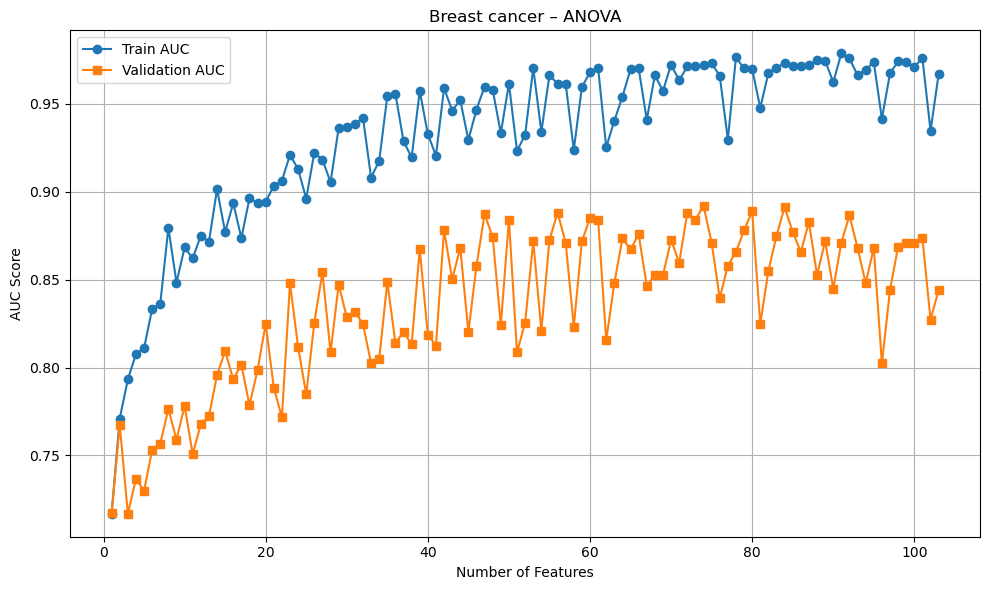

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ANOVA.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Breast cancer – ANOVA")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_ANOVA.png", dpi=300)
plt.show()


### ReliefF

In [1]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "breast_sample_ReliefFSorted.csv"
data = pd.read_csv(file_path)

In [2]:
data

,class,MOTIF_END_ATAT,MOTIF_END_TGCA,MOTIF_END_AAAT,MOTIF_END_AAAC,MOTIF_END_ATTT,MOTIF_END_TGAC,MOTIF_END_ACAC,MOTIF_END_ACAT,MOTIF_END_CAAC,...,CNA_6:112000001-113000000,GWFP_short_7:80000001-85000000,TMD_394,TMD_84,TMD_264,CNA_7:42000001-43000000,CNA_9:85000001-86000000,TMD_83,CNA_2:201000001-202000000,CNA_12:106000001-107000000
0,1,0.005263,0.004784,0.009446,0.005210,0.007665,0.003342,0.004264,0.006115,0.003608,...,1.76609,-0.241803,0.000000,0.140845,0.039124,0.998882,0.469244,1.000000,1.001340,0.970301
1,1,0.005114,0.004583,0.008931,0.005066,0.007451,0.003321,0.004421,0.006049,0.003710,...,1.30208,-0.641215,0.053763,0.086777,0.092674,0.952178,0.472515,0.906250,0.995137,0.991560
2,1,0.005290,0.004733,0.009448,0.005208,0.007627,0.003449,0.004378,0.006350,0.003603,...,1.21608,-0.161835,0.000000,0.156522,0.078947,1.062460,0.502683,1.000000,1.012510,0.979035
3,1,0.005001,0.004872,0.009043,0.005106,0.007338,0.003419,0.004326,0.006024,0.003562,...,1.55770,-0.433488,0.000000,0.138889,0.059361,1.032530,0.488329,0.961538,0.974414,0.986768
4,1,0.005384,0.004480,0.009591,0.005333,0.007579,0.003307,0.004310,0.006151,0.003683,...,1.08071,-0.198100,0.000000,0.189873,0.238138,1.045500,0.521026,1.000000,0.917051,1.023570
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
441,0,0.005366,0.005118,0.009235,0.005238,0.007558,0.003386,0.004246,0.005894,0.003496,...,1.14235,-0.315759,0.000000,0.225000,0.040094,0.978092,0.511960,0.833333,0.973646,0.981343
442,0,0.004996,0.005404,0.008982,0.005048,0.007651,0.003636,0.004168,0.005558,0.003351,...,1.46235,-0.576091,0.062500,0.092199,0.050973,0.953611,0.464046,0.968750,1.007540,0.914902
443,0,0.004540,0.005511,0.008334,0.004732,0.006853,0.003687,0.003973,0.005249,0.003230,...,1.52344,-0.478472,0.000000,0.071429,0.059497,1.017520,0.508417,1.000000,0.997810,0.958421
444,0,0.005202,0.005020,0.009202,0.005154,0.007855,0.003478,0.004260,0.005890,0.003439,...,1.80911,-0.602521,0.062500,0.214286,0.044025,1.013580,0.463640,0.885714,0.971138,0.990718


In [4]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])
X_train

,MOTIF_END_ATAT,MOTIF_END_TGCA,MOTIF_END_AAAT,MOTIF_END_AAAC,MOTIF_END_ATTT,MOTIF_END_TGAC,MOTIF_END_ACAC,MOTIF_END_ACAT,MOTIF_END_CAAC,MOTIF_END_ATAC,...,CNA_6:112000001-113000000,GWFP_short_7:80000001-85000000,TMD_394,TMD_84,TMD_264,CNA_7:42000001-43000000,CNA_9:85000001-86000000,TMD_83,CNA_2:201000001-202000000,CNA_12:106000001-107000000
263,0.004797,0.005122,0.008471,0.004679,0.007021,0.003550,0.003934,0.005382,0.003411,0.002389,...,1.37422,-0.497428,0.000000,0.125000,0.036083,0.910038,0.479148,1.000000,0.989365,0.963400
188,0.004952,0.005180,0.008501,0.004924,0.007681,0.003592,0.004292,0.005591,0.003339,0.002528,...,1.12436,-0.757910,0.000000,0.168317,0.039000,0.929395,0.433497,1.000000,0.999672,0.973422
436,0.004883,0.005342,0.008738,0.004850,0.007279,0.003555,0.004077,0.005706,0.003390,0.002482,...,2.37845,-0.459949,0.176471,0.253731,0.060932,0.952657,0.486959,1.000000,0.968880,0.966470
395,0.004732,0.005177,0.008431,0.004652,0.006675,0.003433,0.003858,0.005370,0.003168,0.002303,...,1.06018,-0.593527,0.052632,0.128440,0.054839,0.988911,0.454134,0.941176,0.964558,0.951118
228,0.005380,0.005360,0.009825,0.005324,0.007833,0.003476,0.004113,0.005681,0.003307,0.002601,...,1.79347,-0.340860,0.000000,0.113208,0.059615,1.040980,0.495681,0.750000,0.992361,1.018200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
193,0.005338,0.005097,0.009403,0.005250,0.007778,0.003528,0.004355,0.006013,0.003533,0.002657,...,1.56425,-0.320868,0.000000,0.136095,0.051058,1.013270,0.490907,1.000000,0.990489,0.991685
88,0.005056,0.004648,0.009093,0.005207,0.007396,0.003247,0.004593,0.006239,0.003598,0.002605,...,1.19051,-0.751615,0.000000,0.176471,0.053247,0.966488,0.433029,1.000000,0.987754,0.954896
444,0.005202,0.005020,0.009202,0.005154,0.007855,0.003478,0.004260,0.005890,0.003439,0.002638,...,1.80911,-0.602521,0.062500,0.214286,0.044025,1.013580,0.463640,0.885714,0.971138,0.990718
304,0.004972,0.005378,0.008899,0.004994,0.007174,0.003555,0.004083,0.005649,0.003334,0.002450,...,2.40606,-0.448094,0.000000,0.161826,0.092429,1.031390,0.470085,0.973333,0.988121,0.985558


In [ ]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [ ]:
all_features = X_train.columns.tolist()
auc_train_scores_ReliefF = []
auc_val_scores_ReliefF = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.2
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [ ]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_ReliefF.append(auc_train)
    auc_val_scores_ReliefF.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >140:
        break
    
    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
{3}
{4}
验证集 AUC 开始下降（0.7843 → 0.7643），连续次数：1
{5}
验证集 AUC 开始下降（0.7643 → 0.7639），连续次数：2
{6}
验证集 AUC 开始下降（0.7639 → 0.7469），连续次数：3
{7}
{8}
{9}
验证集 AUC 开始下降（0.7562 → 0.7531），连续次数：1
{10}
{11}
{12}
验证集 AUC 开始下降（0.7975 → 0.7905），连续次数：1
{13}
验证集 AUC 开始下降（0.7905 → 0.7828），连续次数：2
{14}
{15}
{16}
{17}
验证集 AUC 开始下降（0.8059 → 0.7971），连续次数：1
{18}
验证集 AUC 开始下降（0.7971 → 0.7685），连续次数：2
{19}
{20}
验证集 AUC 开始下降（0.7940 → 0.7681），连续次数：1
{21}
{22}
验证集 AUC 开始下降（0.7955 → 0.7789），连续次数：1
{23}
{24}
验证集 AUC 开始下降（0.7978 → 0.7712），连续次数：1
{25}
{26}
{27}
验证集 AUC 开始下降（0.8040 → 0.7990），连续次数：1
{28}
{29}
验证集 AUC 开始下降（0.8171 → 0.8121），连续次数：1
{30}
验证集 AUC 开始下降（0.8121 → 0.8009），连续次数：2
{31}
验证集 AUC 开始下降（0.8009 → 0.7940），连续次数：3
{32}
{33}
验证集 AUC 开始下降（0.8094 → 0.8032），连续次数：1
{34}
验证集 AUC 开始下降（0.8032 → 0.7901），连续次数：2
{35}
验证集 AUC 开始下降（0.7901 → 0.7847），连续次数：3
{36}
验证集 AUC 开始下降（0.7847 → 0.7562），连续次数：4
{37}
{38}
验证集 AUC 开始下降（0.7562 → 0.7450），连续次数：1
{39}
{40}
验证集 AUC 开始下降（0.7608 → 0.7512），连续次数：1
{41}
验证集 AUC 开始下降（0.7512 → 0.750

In [100]:
breast_sample_ReliefFSorted = pd.read_csv("breast_sample_ReliefFSorted.csv")
breast_sample_ReliefFSorted_selected119 = breast_sample_ReliefFSorted.iloc[:, :120]
breast_sample_ReliefFSorted_selected119.to_csv("../ReliefF/breast_sample_ReliefFSorted_selected119.csv", index=False)

In [ ]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_ReliefF) + 1),
    "Train_AUC": auc_train_scores_ReliefF,
    "Validation_AUC": auc_val_scores_ReliefF
})

auc_df.to_csv("AUC_scores_ReliefF.csv", index=False)

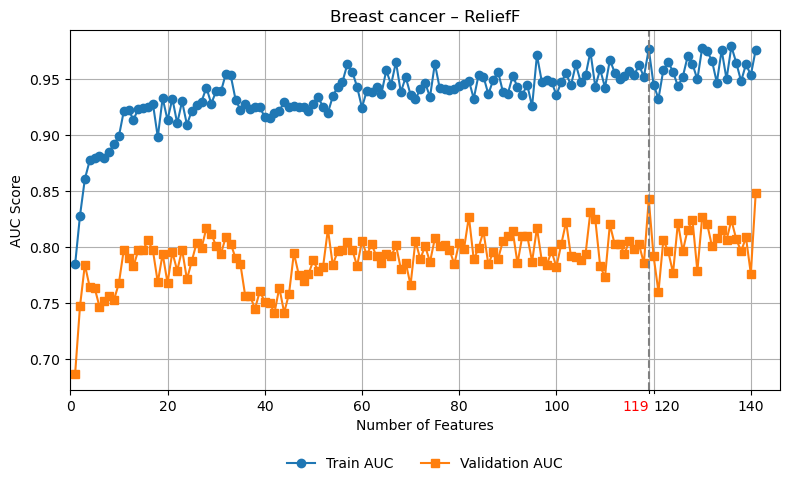

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ReliefF.csv")

# 绘制图像
plt.figure(figsize=(8, 5))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Breast cancer – ReliefF")
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.grid(True)
plt.tight_layout()

# 添加竖线标注特征数 = 119
plt.axvline(x=119, color='gray', linestyle='--', linewidth=1.5)

# 设置 x 轴刻度并强制包含 119
xticks = sorted(set(plt.xticks()[0].tolist() + [119]))
plt.xticks(xticks)

# 调整标签位置
ax = plt.gca()
for label in ax.get_xticklabels():
    text = label.get_text()
    if text == '119':
        # 向左微调0.3个单位，设置右对齐
        label.set_x(label.get_position()[0])
        label.set_horizontalalignment('right')
        label.set_color('red')
        label.set_bbox({'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'none'})
    elif text == '120':
        # 向右微调0.3个单位，设置左对齐
        label.set_x(label.get_position()[0])
        label.set_horizontalalignment('left')
        label.set_bbox({'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'none'})

# 保持网格线在原始位置
ax.xaxis.set_ticks_position('bottom')  # 确保刻度线位置不变

# 调整坐标轴范围防止溢出
ax.set_xlim(left=0, right=max(auc_df["Num_Features"]) + 5)

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_ReliefF.png", dpi=300)
plt.show()


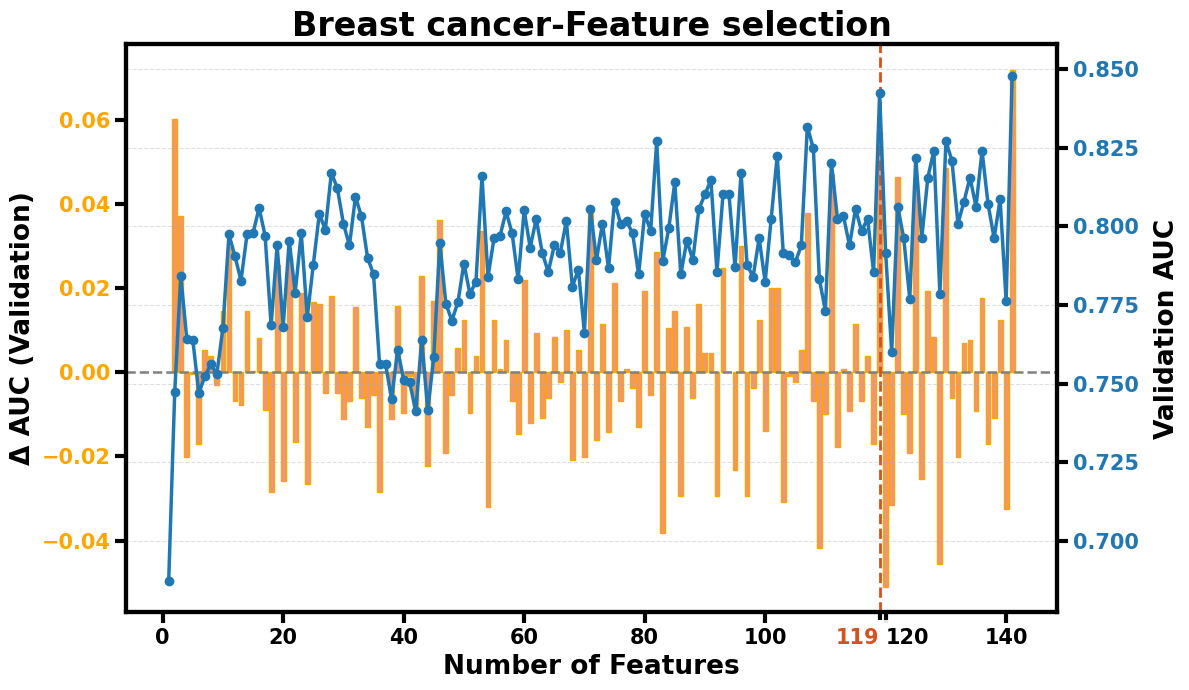

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取数据
auc_df = pd.read_csv("AUC_scores_ReliefF.csv")

# 计算增量
auc_df['Delta_Val_AUC'] = auc_df['Validation_AUC'].diff()

# 设置标记特征数
# highlight_feature = 119
# highlight_index = auc_df[auc_df['Num_Features'] == highlight_feature].index[0]

# 绘图
fig, ax1 = plt.subplots(figsize=(12, 7))

# 柱状图：增量 AUC
bars = ax1.bar(auc_df["Num_Features"], auc_df["Delta_Val_AUC"], color='#ed9678', edgecolor='orange')
ax1.axhline(0, color='gray', linestyle='--', linewidth=1.8)
ax1.set_xlabel("Number of Features", fontsize=19, fontweight='bold')
ax1.set_ylabel("Δ AUC (Validation)", fontsize=19, color='black', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='orange')

# 添加竖线标注特征数 = 119
plt.axvline(x=119, color='#d3521f', linestyle='--', linewidth=2)

# 设置 x 轴刻度并强制包含 119
xticks = sorted(set(plt.xticks()[0].tolist() + [119]))
plt.xticks(xticks)

# 调整标签位置
ax = plt.gca()
for label in ax.get_xticklabels():
    text = label.get_text()
    if text == '119':
        # 向左微调0.3个单位，设置右对齐
        label.set_x(label.get_position()[0])
        label.set_horizontalalignment('right')
        label.set_color('#d3521f')
        label.set_bbox({'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'none'})
    elif text == '120':
        # 向右微调0.3个单位，设置左对齐
        label.set_x(label.get_position()[0])
        label.set_horizontalalignment('left')
        label.set_bbox({'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'none'})

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontsize(15)
    tick_label.set_fontweight('bold')

# 第二轴：叠加 Validation AUC 折线图
ax2 = ax1.twinx()
ax2.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], color='#1f77b4', marker='o', markersize=6, linewidth=2.5, label='Validation AUC')
ax2.set_ylabel("Validation AUC", fontsize=19, color='black', fontweight='bold', labelpad=11)
ax2.tick_params(axis='y', labelcolor='#1f77b4')
ax2.set_ylim(auc_df["Validation_AUC"].min() - 0.01, auc_df["Validation_AUC"].max() + 0.01)

# 图例
# fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.95), frameon=False)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontsize(15)
    tick_label.set_fontweight('bold')

# 美化
plt.title("Breast cancer-Feature selection", fontsize=24, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()

# 保存
plt.savefig("DeltaAUC_and_Trend_Highlight119.png", dpi=300)
plt.show()


### Binomial

In [101]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "breast_sample_BinomialSorted.csv"
data = pd.read_csv(file_path)

In [102]:
data

,class,CNA_1:13000001-14000000,CNA_4:9000001-10000000,TMD_98,TMD_350,CNA_22:21000001-22000000,CNA_16:90000001-90354753,TMD_131,TMD_268,TMD_392,...,GWFP_short_7:150000001-155000000,GWFP_short_10:100000001-105000000,GWFP_short_13:45000001-50000000,GWFP_short_14:25000001-30000000,GWFP_short_20:45000001-50000000,GWFP_total_1:50000001-55000000,GWFP_total_2:60000001-65000000,GWFP_total_5:5000001-10000000,GWFP_total_10:85000001-90000000,flen_152
0,1,0.967960,1.023870,0.000000,0.000000,1.11073,1.27575,0.045977,0.000000,0.000000,...,0.720482,0.612736,0.003412,0.103728,0.837517,0.295014,0.216720,0.680089,-0.306725,0.013033
1,1,0.970525,0.944520,0.000000,0.046512,1.09161,1.32385,0.010183,0.012090,0.002350,...,0.744149,0.890778,-0.303888,-0.024251,1.196050,0.006748,-0.072511,0.951696,-0.026898,0.013470
2,1,0.965195,1.018910,0.000000,0.000000,1.05969,1.10352,0.054054,0.045455,0.000000,...,0.402787,0.756336,0.153268,0.266343,0.916902,0.369438,0.261556,0.789603,-0.339144,0.012692
3,1,0.925010,0.949515,0.000000,0.000000,1.04471,1.20603,0.013423,0.017544,0.000000,...,0.698634,0.933375,-0.013637,-0.064610,1.064830,0.112351,0.038339,0.795761,-0.277727,0.011777
4,1,1.255090,1.226660,0.300813,0.000000,1.02235,1.30905,0.000000,0.005464,0.513513,...,0.745337,0.951623,0.290929,0.430137,1.090110,0.497400,-0.333068,0.815343,-0.249832,0.014815
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
441,0,0.923612,0.921408,0.037037,0.000000,1.03597,1.42804,0.003597,0.000000,0.000000,...,0.885863,0.977997,-0.121112,-0.156148,1.020820,0.122417,-0.076940,0.735091,-0.280949,0.012246
442,0,0.958038,0.920887,0.012048,0.000000,1.09585,1.53302,0.011038,0.000000,0.005000,...,0.780745,0.737815,-0.520733,-0.246767,0.988620,-0.071438,-0.207154,1.053650,-0.043288,0.011996
443,0,0.983011,0.906756,0.000000,0.000000,1.04088,1.41372,0.020000,0.000000,0.000000,...,0.944696,0.829375,-0.593794,-0.250451,0.828064,-0.045787,-0.209144,0.884823,-0.122059,0.013084
444,0,0.928419,0.900363,0.000000,0.000000,1.07485,1.32900,0.034091,0.032051,0.000000,...,0.783552,0.883126,-0.167050,-0.144480,0.771603,0.093037,-0.055078,0.878087,-0.203193,0.011022


In [103]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [ ]:
all_features = X_train.columns.tolist()
auc_train_scores_Binomial = []
auc_val_scores_Binomial = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.25
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 30
max_decline_tolerance = 5

In [ ]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_Binomial.append(auc_train)
    auc_val_scores_Binomial.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >250:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
验证集 AUC 开始下降（0.5579 → 0.5382），连续次数：1
{3}
{4}
{5}
验证集 AUC 开始下降（0.6852 → 0.5683），连续次数：1
{6}
{7}
验证集 AUC 开始下降（0.5710 → 0.5625），连续次数：1
{8}
{9}
验证集 AUC 开始下降（0.5725 → 0.5521），连续次数：1
{10}
过拟合检测：训练集 AUC=0.8179, 验证集 AUC=0.5656，连续次数：1
{11}
验证集 AUC 开始下降（0.5656 → 0.5629），连续次数：1
{12}
{13}
验证集 AUC 开始下降（0.5883 → 0.5880），连续次数：1
{14}
过拟合检测：训练集 AUC=0.8507, 验证集 AUC=0.5432，连续次数：1
验证集 AUC 开始下降（0.5880 → 0.5432），连续次数：2
{15}
过拟合检测：训练集 AUC=0.8631, 验证集 AUC=0.5880，连续次数：2
{16}
过拟合检测：训练集 AUC=0.8644, 验证集 AUC=0.5849，连续次数：3
验证集 AUC 开始下降（0.5880 → 0.5849），连续次数：1
{17}
{18}
验证集 AUC 开始下降（0.7037 → 0.6644），连续次数：1
{19}
验证集 AUC 开始下降（0.6644 → 0.6636），连续次数：2
{20}
{21}
验证集 AUC 开始下降（0.6944 → 0.6427），连续次数：1
{22}
{23}
验证集 AUC 开始下降（0.6829 → 0.6651），连续次数：1
{24}
验证集 AUC 开始下降（0.6651 → 0.6644），连续次数：2
{25}
{26}
验证集 AUC 开始下降（0.7060 → 0.6879），连续次数：1
{27}
验证集 AUC 开始下降（0.6879 → 0.6759），连续次数：2
{28}
验证集 AUC 开始下降（0.6759 → 0.6651），连续次数：3
{29}
{30}
验证集 AUC 开始下降（0.6721 → 0.6628），连续次数：1
{31}
{32}
验证集 AUC 开始下降（0.6782 → 0.6235），连续次数：1
{33}
{3

In [5]:
breast_sample_BinomialSorted = pd.read_csv("breast_sample_BinomialSorted.csv")
breast_sample_BinomialSorted_selected230 = breast_sample_BinomialSorted.iloc[:, :231]
breast_sample_BinomialSorted_selected230.to_csv("../Binomial/breast_sample_BinomialSorted_selected230.csv", index=False)

In [ ]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_Binomial) + 1),
    "Train_AUC": auc_train_scores_Binomial,
    "Validation_AUC": auc_val_scores_Binomial
})

auc_df.to_csv("AUC_scores_Binomial.csv", index=False)

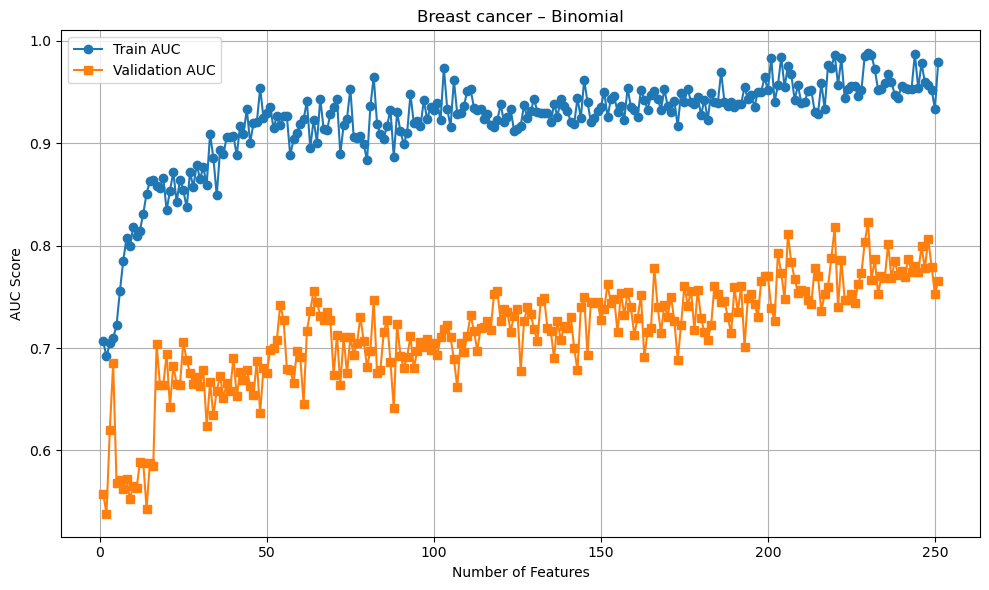

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_Binomial.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Breast cancer – Binomial")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_Binomial.png", dpi=300)
plt.show()

### biomaker分析

In [27]:
import pandas as pd

file_paths = [
    "../ANOVA/breast_sample_AnovaSorted_selected74.csv",
    "../Binomial/breast_sample_BinomialSorted_selected230.csv",
    "../Fscore/breast_sample_FscoreSorted_selected74.csv",
    "../ReliefF/breast_sample_ReliefFSorted_selected119.csv"
]
dfs = [pd.read_csv(file_path) for file_path in file_paths]
dfs_info = [df.head() for df in dfs]


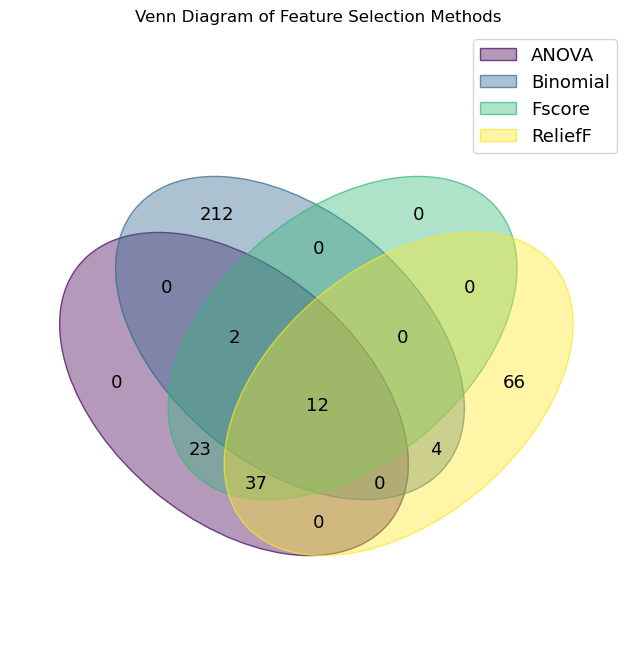

In [30]:
import matplotlib.pyplot as plt
from venn import venn
import pandas as pd

# 加载所有文件
df_anova = dfs[0]
df_binomial = dfs[1]
df_fscore = dfs[2]
df_reliefF = dfs[3]

# 提取每个文件的特征列
anova_features = set(df_anova.columns[1:])
binomial_features = set(df_binomial.columns[1:])
fscore_features = set(df_fscore.columns[1:])
relieff_features = set(df_reliefF.columns[1:])

feature_sets = {
    'ANOVA': anova_features,
    'Binomial': binomial_features,
    'Fscore': fscore_features,
    'ReliefF': relieff_features
}

venn(feature_sets)
plt.title("Venn Diagram of Feature Selection Methods")
plt.show()